# **Capitolo 4. Analisi del Dataset delle Recensioni Clienti**

L'attenzione si sposta sul **dataset delle recensioni dei clienti**, analizzato attraverso tre fasi: data cleaning e analisi esplorativa; esplorazione più approfondita del dato testuale; estrazione del sentiment tramite tecniche di NLP, fino alla costruzione di un indice di coerenza percettiva. 

> Questo primo notebook riguardante le procedure descritte nel quarto capitolo, si occupa della pulizia, integrità e di una prima analisi statistica dell'interono dataset (*inizio del capitolo 4 e paragrafo 4.1, incluso con annessi sottoparagrafi*).

Prepariamo l'ambiente di lavoro e carichiamo le informazioni grezze estratte.

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from IPython.display import display, HTML

while not os.path.exists("Circular Second Hand") and os.getcwd() != os.path.dirname(os.getcwd()):
    os.chdir("..")

print(f"Jupyter è allineato. Cartella di lavoro attuale:\n{os.getcwd()}.\n")


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [3]:
cartella_recensioni = os.path.join("Circular Second Hand", "Recensioni", "Dati - Recensioni")
pattern_cartelle = os.path.join(cartella_recensioni, "Estrazione__*")
lista_cartelle = [d for d in glob.glob(pattern_cartelle) if os.path.isdir(d)]

if not lista_cartelle:
    print(f"ERRORE: Nessuna cartella 'Estrazione__*' trovata in {cartella_recensioni}.")
    raise SystemExit(1)

cartella_recente = max(lista_cartelle)
print(f"Cartella di estrazione più recente: {cartella_recente}.")

pattern_file_recensioni = os.path.join(cartella_recente, "recensioni_usato__*.csv")
lista_file_recensioni = glob.glob(pattern_file_recensioni)

if not lista_file_recensioni:
    print(f"ERRORE: Nessun file 'recensioni_usato__*.csv' trovato nella cartella {cartella_recente}.")
    raise SystemExit(1)

file_recensioni = max(lista_file_recensioni)
print(f"File Recensioni identificato: {file_recensioni}.")

Cartella di estrazione più recente: Circular Second Hand\Recensioni\Dati - Recensioni\Estrazione__20260408__170730.
File Recensioni identificato: Circular Second Hand\Recensioni\Dati - Recensioni\Estrazione__20260408__170730\recensioni_usato__20260408__170730.csv.


In [4]:
try:
    df = pd.read_csv(file_recensioni, dtype={'Numero Articolo Catalogo': str})
    print("\nDataset delle recensioni letto con successo!")
    display(HTML(f"<b>Righe totali</b>: {df.shape[0]}. <br><b>Colonne totali</b>: {df.shape[1]}."))
    
except FileNotFoundError as e:
    print(f"Errore durante la lettura: {e}. Assicurarsi che i file esistano.")
    raise SystemExit(1)


Dataset delle recensioni letto con successo!


## **4.1. Pulizia, integrità e analisi statistica**

Si racchiudono qui, in primis, le operazioni necessarie per **trasformare il dataset grezzo in un database** pronto per l'analisi statistica: deduplicazione, pruning, ispezione dei valori distinti, standardizzazione logica, normalizzazione temporale.

In [ ]:
# DEDUPLICAZIONE E PRUNING
# Ricerca righe duplicate e gestione
duplicati_totali = df.duplicated().sum()

if duplicati_totali > 0:
    print(f"Trovate {duplicati_totali} righe interamente duplicate. Si procede con la rimozione...")
    df.drop_duplicates(inplace=True)
    display(HTML(f"Rimozione completata. Nuovo numero di <b>righe totali</b>: {df.shape[0]}."))
    
else:
    display(HTML("<b>Nessuna riga</b> duplicata trovata."))
    
# Ricerca colonne vuote e gestione
colonne_da_eliminare = []

for col in df.columns:
    valori_vuoti_o_trattini = df[col].isin(['-', np.nan]).sum()
    
    if valori_vuoti_o_trattini == len(df):
        colonne_da_eliminare.append(col)

if len(colonne_da_eliminare) > 0:
    print(f"\nTrovate {len(colonne_da_eliminare)} colonne interamente vuote:")
    for col in colonne_da_eliminare:
        print(f"  - {col}")
    df.drop(columns=colonne_da_eliminare, inplace=True)
    display(HTML(f"Colonne rimosse con successo. Nuovo numero di <b>colonne totali</b>: {df.shape[1]}."))

else:
    display(HTML("<b>Nessuna colonna</b> interamente vuota individuata."))


Trovate 2 colonne interamente vuote:
  - Voto: Facilità di preparazione
  - Voto: Gusto


In [ ]:
# ISPEZIONE DEI VALORI DISTINTI
display(HTML("<h3 >--- <b>ISPEZIONE VALORI DISTINTI PER COLONNA ---</h3>"))

for col in df.columns:
    # Calcoliamo i conteggi includendo anche i valori mancanti
    conteggi = df[col].value_counts(dropna=False)
    num_distinti = len(conteggi)
    
    display(HTML(f"<b>Colonna: '<span style='color: #e35205;'>{col}</span>' | Valori distinti: {num_distinti}"))
    
    if num_distinti <= 7:
        # Trasformiamo la Series in un bel DataFrame a 2 colonne
        df_visivo = conteggi.reset_index()
        df_visivo.columns = ['Valore', 'Conteggio']
        
        # Facciamo partire l'indice da 1 invece che da 0 e mostriamo la tabella formattata
        df_visivo.index = df_visivo.index + 1
        display(df_visivo)
    
    else:
        display(HTML("<i>Primi 3 valori più frequenti:"))
        
        # Prendiamo solo i primi 3, trasformandoli in DataFrame
        df_visivo = conteggi.head(3).reset_index()
        df_visivo.columns = ['Valore', 'Conteggio']
        
        # Facciamo partire l'indice da 1 invece che da 0 e mostriamo la tabella formattata
        df_visivo.index = df_visivo.index + 1
        display(df_visivo)
    
    display(HTML("<hr style='border-top: 1px solid #d3d3d3; margin-top: 5px; margin-bottom: 15px;'>"))


### [Output rimosso per tutela della privacy e riservatezza commerciale]

Definiamo la natura logica delle singole colonne al fine di applicare una gestione coerente e semanticamente corretta dei valori mancanti (originariamente estratti come trattini '-'). Le variabili vengono quindi classificate nei seguenti gruppi:

* **Numeriche**: per le colonne di voto, il trattino indica una valutazione non fornita dall’utente e viene convertito in `NaN`, così da non introdurre distorsioni nelle analisi statistiche (come nelle medie). Per la colonna Like, invece, il trattino rappresenta semanticamente l’assenza di interazioni e viene quindi convertito in `0`.

* **Temporali**: includono le date di recensione e di estrazione, mantenute nel loro formato originale per successive trasformazioni (parsing in datetime).

* **Booleane**: la colonna Raccomandato prevede valori testuali `"True"` e `"False"`, i quali vengono mappati nei corrispondenti valori booleani; i falsi vuoti di sistema (`-`, `None`, `none`) vengono invece convertiti in `NaN`, garantendo coerenza con la semantica di dato mancante.

* **Categoriali**: ovvero tutte le restanti colonne (Titolo, Testo, Utente, ID). In questo caso, i falsi vuoti di sistema (`None`, `none`) vengono uniformati al trattino `-`, che viene mantenuto come rappresentazione esplicita di valore mancante. Il trattino non viene convertito in `NaN` per evitare problemi nelle successive elaborazioni testuali e mantenere coerenza con il formato originale dei dati.

In [ ]:
# STANDARDIZZAZIONE LOGICA E GESTIONE DEI MISSING

colonne_numeriche = ['Voto Generale Recensione', 'Voto: Estetica', 'Voto: Facilità di montaggio/installazione',
                    'Voto: Come valuti la qualità del prodotto?', 'Voto: Rapporto qualità/prezzo',
                    'Voto: Soddisfa le mie aspettative', 'Voto: Facilità di preparazione',
                    'Voto: Aiuta a risparmiare energia e/o acqua', 'Voto: Aiuta a ridurre/differenziare i rifiuti',
                    'Voto: Gusto', 'Like']

colonne_temporali = ['Data Recensione', 'Timestamp Estrazione Recensione']

colonne_booleane = ['Raccomandato']

# Tutte le altre colonne presenti nel dataframe restano categoriali/testuali
colonne_testuali = [col for col in df.columns if col not in colonne_numeriche + colonne_temporali + colonne_booleane]

# Gestione dedicata alle colonne numeriche
for col in colonne_numeriche:
    if col in df.columns:
        # Pulizia base (importantissima)
        df[col] = df[col].astype(str).str.strip()
        
        if col == 'Like':
            df[col] = df[col].replace('-', 0)
        else:
            df[col] = df[col].replace('-', np.nan)

        df[col] = pd.to_numeric(df[col], errors='coerce')

# Gestione dedicata alla colonna Raccomandato
if 'Raccomandato' in df.columns:
    # Mappiamo le stringhe testuali in veri booleani e i trattini/None in NaN, poi forziamo il tipo
    mappatura_booleana = {'True': True, 'False': False, '-': np.nan, 'None': np.nan, 'none': np.nan}
    df['Raccomandato'] = df['Raccomandato'].replace(mappatura_booleana).astype('boolean')

# Gestione dedicata alle colonne categoriali (standardizzazione falsi vuoti informatici)
for col in colonne_testuali:
    if col in df.columns:
        # Uniformiamo i "falsi vuoti" informatici nel nostro standard visivo stabilito: il trattino '-'
        df[col] = df[col].replace(['None', 'none', np.nan], '-')

print("\nClassificazione completata e valori mancanti (inclusi i 'None' di sistema) gestiti correttamente.")


Classificazione completata e valori mancanti (inclusi i 'None' di sistema) gestiti correttamente.


In [ ]:
# NORMALIZZAZIONE TEMPORALE DINAMICA
display(HTML("<h3 >--- <b>NORMALIZZAZIONE TEMPORALE (GESTIONE FORMATI MISTI) ---</h3>"))

def normalizza_date_miste(serie):
    # Lista dei formati di date più probabili
    formati_da_testare = [
        '%Y%m%d__%H%M%S',       # Il nostro formato attuale prevalente (es. 20220116__153058)
        '%Y-%m-%d %H:%M:%S',    # Standard DB ISO (es. 2022-01-16 15:30:58)
        '%d/%m/%Y %H:%M:%S',    # Formato Europeo classico (es. 16/01/2022 15:30:58)
        '%Y-%m-%dT%H:%M:%S',    # Formato API ISO 8601 (es. 2022-01-16T15:30:58)
        '%Y-%m-%d',             # Solo data (es. 2022-01-16)
        '%d/%m/%Y'              # Solo data europea (es. 16/01/2022)
    ]
     
    # Inizializziamo una Series vuota (piena di NaT) e un dizionario per il report dei formati
    risultato = pd.Series(pd.NaT, index=serie.index)
    report_formati = {}
    
    # Applichiamo i formati a cascata
    for formato in formati_da_testare:
        # Filtriamo solo le righe che non siamo ancora riusciti a convertire E che non sono già nulle
        da_convertire = serie[risultato.isna() & serie.notna()]
        
        if da_convertire.empty:
            break
            
        # Proviamo la conversione. Ciò che non fa match con il formato corrente diventa NaT.
        tentativo = pd.to_datetime(da_convertire, format=formato, errors='coerce')
        
        # Contiamo quanti successi abbiamo ottenuto con questo formato
        successi = tentativo.notna().sum()
        if successi > 0:
            report_formati[formato] = successi
            risultato = risultato.fillna(tentativo)
        
    # Fallback finale per date con formati imprevisti
    rimanenti = serie[risultato.isna() & serie.notna()]
    if not rimanenti.empty:
        tentativo_fallback = pd.to_datetime(rimanenti, errors='coerce')
        successi_fallback = tentativo_fallback.notna().sum()
        
        if successi_fallback > 0:
            report_formati['Fallback automatico di Pandas'] = successi_fallback
            risultato = risultato.fillna(tentativo_fallback)
            
    return risultato, report_formati

# Applichiamo la nostra logica alle colonne temporali
for col in colonne_temporali:
    # Controlliamo che la colonna esista e non sia del tutto vuota
    if col in df.columns and not df[col].dropna().empty:
        
        # Salviamo il numero di valori validi originali per un confronto
        valori_iniziali = df[col].notna().sum()
        
        # Applichiamo la funzione a cascata ricevendo in output sia la serie che il report
        df[col], formati_rilevati = normalizza_date_miste(df[col])
        
        # Stampiamo il report generale
        valori_convertiti = df[col].notna().sum()
        display(HTML(f"Colonna '<b>{col}</b>': normalizzata. Valori convertiti: {valori_convertiti}/{valori_iniziali}."))
        
        # Stampiamo il dettaglio dei formati intercettati
        if formati_rilevati:
            lista_html = "".join([f"<li>Formato <b>{k}</b>: {v} valori</li>" for k, v in formati_rilevati.items()])
            display(HTML(f"<ul style='margin-top: 0px; margin-bottom: 15px;'>{lista_html}</ul>"))

display(HTML("<b>Date convertite con successo in formato Datetime.</b>"))

Procediamo con l'analisi esplorativa di base, arricchita da insight di business dinamici.

In [ ]:
# ANALISI VARIABILI NUMERICHE
pd.set_option('display.max_columns', None)

display(HTML("<h3>--- <b>ANALISI STATISTICA UNIVARIATA</b> ---</h3>"))

# Variabili numeriche
col_num_attive = [col for col in colonne_numeriche if col in df.columns]

if col_num_attive:
    display(HTML("<h4><b>Variabili Numeriche</b></h4>"))
    
    # Describe classico con l'aggiunta dell'asimmetria e della percentuale di missing
    stats_num = df[col_num_attive].describe().T
    stats_num['skewness'] = df[col_num_attive].skew()
    stats_num['% missing'] = ((df[col_num_attive].isna().sum() / len(df)) * 100).round(2)

    stats_num = stats_num[['count', '% missing', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness']]
    display(stats_num.round(2))
    
    # Generazione Insight Automatici 
    display(HTML("<br><b>Insight e osservazioni automatiche</b>:<ul>"))
    
    for col in col_num_attive:
        skew = df[col].skew()
        missing_perc = round((df[col].isna().sum() / len(df)) * 100, 2)
        
        insight_frasi = []
        
        # Logica per i valori mancanti (soglia di allarme al 60%)
        if missing_perc > 60:
            insight_frasi.append(f"<b>{missing_perc}%</b> di valori mancanti.")
            
        # Logica per i voti (escludiamo i Like per logiche diverse)
        if col != 'Like':
            if skew < -1:
                insight_frasi.append("Forte asimmetria a sinistra: i giudizi sono concentrati sui valori alti")
            elif skew > 1:
                insight_frasi.append("Asimmetria a destra: maggiore presenza di valutazioni basse")
                
        # Logica esclusiva per la colonna Like
        if col == 'Like':
            perc_zero_like = round(((df[col] == 0).sum() / len(df)) * 100, 2)
            max_like = df[col].max()
            
            # Valutazione dinamica della skewness per i Like
            if skew > 3:
                insight_frasi.append(f"Estrema asimmetria a destra (Skew: <b>{round(skew, 2)}</b>).")
            elif skew > 1:
                insight_frasi.append(f"Forte asimmetria a destra (Skew: <b>{round(skew, 2)}</b>).")
            elif skew < -1:
                insight_frasi.append(f"Asimmetria a sinistra (Skew: <b>{round(skew, 2)}</b>).")
            else:
                insight_frasi.append(f"Distribuzione tendenzialmente simmetrica (Skew: <b>{round(skew, 2)}</b>).")

            insight_frasi.append(f"Il <b>{perc_zero_like}%</b> delle recensioni non ha ricevuto alcun Like.")
            insight_frasi.append(f"La recensione più virale ha totalizzato <b>{max_like}</b> Like")
            
        # Stampa l'insight solo se la colonna ha registrato almeno una delle condizioni sopra
        if insight_frasi:
            testo_unito = " ||| ".join(insight_frasi)
            display(HTML(f"<li><b>{col}</b> ➔ {testo_unito}.</li>"))

    display(HTML("</ul>"))

,count,% missing,mean,std,min,25%,50%,75%,max,skewness
Voto Generale Recensione,97545.0,0.00,4.48,0.93,1.0,4.0,5.0,5.0,5.0,-2.14
Voto: Estetica,95035.0,2.57,4.50,0.80,1.0,4.0,5.0,5.0,5.0,-1.90
Voto: Facilità di montaggio/installazione,74181.0,23.95,4.55,0.86,1.0,4.0,5.0,5.0,5.0,-2.30
Voto: Come valuti la qualità del prodotto?,95065.0,2.54,4.34,0.95,1.0,4.0,5.0,5.0,5.0,-1.72
Voto: Rapporto qualità/prezzo,95248.0,2.35,4.43,0.91,1.0,4.0,5.0,5.0,5.0,-1.89
Voto: Soddisfa le mie aspettative,94065.0,3.57,4.51,0.94,1.0,4.0,5.0,5.0,5.0,-2.29
Voto: Aiuta a risparmiare energia e/o acqua,4524.0,95.36,4.16,1.06,1.0,4.0,4.0,5.0,5.0,-1.34
Voto: Aiuta a ridurre/differenziare i rifiuti,1750.0,98.21,4.42,1.03,1.0,4.0,5.0,5.0,5.0,-1.97
Like,97545.0,0.00,0.48,2.58,0.0,0.0,0.0,0.0,266.0,33.16


In [ ]:
# ANALISI VARIABILE BOOLEANA
col_bool_attive = [col for col in colonne_booleane if col in df.columns]

if col_bool_attive:
    display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))
    display(HTML("<h4><b>Variabili Booleane</b></h4>"))
    
    for col in col_bool_attive:
        # Tabella standard accompagnata dalla percentuale sul totale
        conteggi = df[col].value_counts(dropna=False).reset_index()
        conteggi.columns = ['Stato', 'Conteggio Assoluto']
        conteggi['Percentuale sul Totale (%)'] = ((conteggi['Conteggio Assoluto'] / len(df)) * 100).round(2)
        
        display(HTML(f"Distribuzione per la colonna: <b>{col}</b>"))
        display(conteggi)
        
        # Generazione Insight Automatici
        display(HTML("<br><b>Insight e osservazioni automatiche</b>:<ul>"))
        
        # Calcolo sul totale del dataset (inclusi i missing)
        perc_true_totale = round(((df[col] == True).sum() / len(df)) * 100, 2)
        
        # Calcolo solo sui rispondenti effettivi (esclusi i missing)
        valori_validi = df[col].notna().sum()
        perc_true_validi = round(((df[col] == True).sum() / valori_validi) * 100, 2) if valori_validi > 0 else 0
        
        insight_frasi = []
        
        if col == 'Raccomandato':
            # Aggiungiamo l'insight sul totale
            insight_frasi.append(f"Rispetto all'intero dataset, il <b>{perc_true_totale}%</b> di tutte le estrazioni <b>raccomanda</b> l'acquisto.")
            
            # Logica dinamica per il tasso di approvazione reale (sui validi)
            if perc_true_validi > 90:
                insight_frasi.append(f"Isolando solo chi ha espresso un'opinione, emerge un elevatissimo tasso di raccomandazione: <b>{perc_true_validi}%</b>")
            elif perc_true_validi > 75:
                insight_frasi.append(f"Isolando chi si è espresso, emerge un forte tasso di approvazione: <b>{perc_true_validi}%</b>")
            elif perc_true_validi > 50:
                insight_frasi.append(f"Approvazione moderata tra i rispondenti: <b>{perc_true_validi}%</b>")
            else:
                insight_frasi.append(f"Solo il <b>{perc_true_validi}%</b> di chi si è espresso raccomanda l'acquisto")
                
        # Stampa l'insight solo se la colonna ha registrato le condizioni
        if insight_frasi:
            testo_unito = " ||| ".join(insight_frasi)
            display(HTML(f"<li><b>{col}</b> ➔ {testo_unito}.</li>"))
            
    display(HTML("</ul>"))

,Stato,Conteggio Assoluto,Percentuale sul Totale (%)
0,True,88913,91.15
1,False,4717,4.84
2,<NA>,3915,4.01


In [ ]:
# ANALISI VARIABILI CATEGORIALI/TESTUALI
col_test_attive = [col for col in colonne_testuali if col in df.columns]

if col_test_attive:
    display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))
    display(HTML("<h4><b>Variabili Categoriali</b></h4>"))
    
    metriche = []
    
    for col in col_test_attive:
        totale = len(df)
        unici = df[col].nunique()
        
        # Unifichiamo NaN veri e trattini come Valore Mancante
        missing = df[col].isna().sum() + (df[col] == '-').sum()
        perc_missing = round((missing / totale) * 100, 2)
        validi = totale - missing
        
        # Lunghezza media testo
        serie_valida = df[col].replace('-', np.nan).dropna().astype(str)
        lunghezza_media = serie_valida.str.len().mean() if not serie_valida.empty else 0
        
        # Moda e tipologia di distribuzione
        if unici == totale:
            top = "Valori tutti univoci"
            tipo_moda = "Univoca"
        else:
            conteggi = df[col][df[col] != '-'].value_counts()
            if not conteggi.empty:
                max_freq = conteggi.iloc[0] 
                mode_values = conteggi[conteggi == max_freq].index.tolist()
                
                if len(mode_values) == 1:
                    top = str(mode_values[0])
                    tipo_moda = "Unimodale"
                elif len(mode_values) == 2:
                    top = f"{mode_values[0]} e {mode_values[1]}"
                    tipo_moda = "Bimodale"
                else:
                    top = ", ".join(map(str, mode_values[:3])) + ("..." if len(mode_values) > 3 else "")
                    tipo_moda = f"Multimodale ({len(mode_values)} mode)"
            else:
                top = "Nessuno"
                tipo_moda = "Assente"
        
        metriche.append({'Colonna': col, 'Count (validi)': validi, 'Valori Unici': unici, 'Tipo Distribuzione': tipo_moda,
                         'Top': top, 'Lunghezza media del testo': round(lunghezza_media, 1), '% missing': perc_missing})
        
    stats_cat = pd.DataFrame(metriche).set_index('Colonna')
    display(stats_cat)
    
    # Generazione Insight Automatici 
    display(HTML("<br><b>Insight e osservazioni automatiche</b>:<ul>"))
    
    for col in col_test_attive:
        unici = df[col].nunique()
        perc_missing = round(((df[col].isna().sum() + (df[col] == '-').sum()) / len(df)) * 100, 2)
        
        insight_frasi = []
        
        # Check di struttura generale
        if unici == len(df):
            insight_frasi.append("Identificativo di sistema perfettamente univoco")
        elif perc_missing > 90:
            insight_frasi.append(f"Dato quasi del tutto assente (<b>{perc_missing}%</b> di valori mancanti)")
                   
        # Check di business specifici
        if col == 'Utente Recensione':
            num_anonimi = df[col].str.lower().isin(['revisore anonimo', 'anonymous']).sum()
            perc_anonimi = round((num_anonimi / len(df)) * 100, 2)
            
            # Scaglioni dinamici per l'anonimato
            if perc_anonimi >= 70:
                insight_frasi.append(f"Elevatissimo tasso di anonimato (<b>{perc_anonimi}%</b>)")
            elif perc_anonimi >= 40:
                insight_frasi.append(f"Forte presenza di utenti anonimi (<b>{perc_anonimi}%</b>)")
            else:
                insight_frasi.append(f"Solo il <b>{perc_anonimi}%</b> opta per l'anonimato")
            
        elif col == 'Numero Articolo Catalogo':
            top_recensioni = df[col].value_counts().max()
            
            if top_recensioni > (len(df) * 0.10): # Se un solo prodotto ha più del 10% di tutte le recensioni
                insight_frasi.append(f"Forte concentrazione: l'articolo top ha ben <b>{top_recensioni}</b> recensioni")
            else:
                insight_frasi.append(f"Interesse distribuito. L'articolo con più review ne conta <b>{top_recensioni}</b>")
             
        elif col == 'Risposta [redacted]':
            validi_[redacted] = stats_cat.loc[col, 'Count (validi)']
            perc_[redacted] = round((validi_[redacted] / len(df)) * 100, 2)
            
            # Scaglioni dinamici per il Customer Care
            if perc_[redacted] == 0:
                 insight_frasi.append("L'azienda non ha risposto a nessuna recensione")
            elif perc_[redacted] < 10:
                 insight_frasi.append(f"Customer Care a bassa reattività: ha risposto a sole <b>{validi_[redacted]}</b> recensioni (il {perc_[redacted]}%)")
            elif perc_[redacted] < 50:
                 insight_frasi.append(f"Customer Care moderato: ha gestito <b>{validi_[redacted]}</b> recensioni (il {perc_[redacted]}%)")
            else:
                 insight_frasi.append(f"Forte presenza del brand: interviene nel <b>{perc_[redacted]}%</b> dei casi")

        if insight_frasi:
            testo_unito = " ||| ".join(insight_frasi)
            display(HTML(f"<li><b>{col}</b> ➔ {testo_unito}.</li>"))

    display(HTML("</ul>"))


### [Output rimosso per tutela della privacy e riservatezza commerciale]

In [ ]:
# ANALISI VARIABILI TEMPORALI
col_temp_attive = [col for col in colonne_temporali if col in df.columns]

if col_temp_attive:
    display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))
    display(HTML("<h4><b>Variabili Temporali</b></h4>"))
    
    for col in col_temp_attive:
        data_min = df[col].min()
        data_max = df[col].max()
        
        if pd.notna(data_min) and pd.notna(data_max):
            durata = data_max - data_min
            
            durata_str = str(durata).split('.')[0] 
            
            display(HTML(f"Distribuzione per la colonna: <b>{col}</b>"))
            display(HTML(f"<ul>"
                         f"<li>Da: <b>{data_min}</b> a: <b>{data_max}</b></li>"
                         f"<li>Durata temporale misurata: <b>{durata_str}</b></li>"
                         f"</ul>"))
            
            # Insight automatico temporale
            if durata.days < 2:
                display(HTML(f"Insight: variabile tecnica (legata al momento dell'estrazione web).<br><br>"))
            else:
                display(HTML(f"Insight: variabile informativa (idonea per analisi temporali sulle recensioni).<br><br>"))

### **4.1.1. Approfondimenti mirati**

Si supera la descrizione univariata attraverso alcuni **approfondimenti finalizzati a individuare le principali relazioni tra le variabili**.

-> **I driver della soddisfazione**

In [13]:
col_voti = [col for col in colonne_numeriche if 'Voto' in col and col in df.columns]

if len(col_voti) > 1:
    display(HTML("<h4><b>Correlazione tra i voti</b> (Indice di Spearman)</h4>"))
    
    # Matrice di correlazione usando Spearman
    corr_matrix = df[col_voti].corr(method='spearman').round(2)
    
    # Heatmap
    display(corr_matrix.style.background_gradient(cmap='Blues', axis=None).format(precision=2))
    
    # Insight dinamico (Puramente Matematico)
    if 'Voto Generale Recensione' in corr_matrix.columns:
        correlazioni_generale = corr_matrix['Voto Generale Recensione'].drop('Voto Generale Recensione')
        if not correlazioni_generale.empty and not correlazioni_generale.isna().all():
            
            # Estrazione puramente statistica dei primi due driver
            top_drivers = correlazioni_generale.nlargest(2)
            
            primo_driver = top_drivers.index[0]
            primo_valore = top_drivers.iloc[0]
            
            secondo_driver = top_drivers.index[1]
            secondo_valore = top_drivers.iloc[1]
            
            display(HTML("<ul>"))
            display(HTML(f"<li><b>Primo Driver Statistico:</b> La variabile più fortemente correlata al Voto Generale è <b>{primo_driver}</b> (Indice di Spearman: <b>{primo_valore}</b>).</li>"))
            display(HTML(f"<li><b>Secondo Driver Statistico:</b> La successiva variabile per forza di correlazione è <b>{secondo_driver}</b> (Indice di Spearman: <b>{secondo_valore}</b>).</li>"))
            display(HTML("</ul>"))

,Voto Generale Recensione,Voto: Estetica,Voto: Facilità di montaggio/installazione,Voto: Come valuti la qualità del prodotto?,Voto: Rapporto qualità/prezzo,Voto: Soddisfa le mie aspettative,Voto: Aiuta a risparmiare energia e/o acqua,Voto: Aiuta a ridurre/differenziare i rifiuti
Voto Generale Recensione,1.00,0.60,0.52,0.71,0.65,0.73,0.56,0.47
Voto: Estetica,0.60,1.00,0.49,0.65,0.57,0.62,0.49,0.50
Voto: Facilità di montaggio/installazione,0.52,0.49,1.00,0.53,0.51,0.59,0.48,0.62
Voto: Come valuti la qualità del prodotto?,0.71,0.65,0.53,1.00,0.69,0.69,0.63,0.49
Voto: Rapporto qualità/prezzo,0.65,0.57,0.51,0.69,1.00,0.66,0.57,0.52
Voto: Soddisfa le mie aspettative,0.73,0.62,0.59,0.69,0.66,1.00,0.59,0.50
Voto: Aiuta a risparmiare energia e/o acqua,0.56,0.49,0.48,0.63,0.57,0.59,1.00,nan
Voto: Aiuta a ridurre/differenziare i rifiuti,0.47,0.50,0.62,0.49,0.52,0.50,nan,1.00


-> **Coerenza logica: il sospetto sulla raccomandazione**

In [ ]:
if 'Voto Generale Recensione' in df.columns and 'Raccomandato' in df.columns:
    display(HTML("<h4><b>Coerenza Logica: Voto vs Raccomandazione</b></h4>"))

    # Isoliamo i record con entrambe le informazioni valorizzate
    df_logic = df.dropna(subset=['Voto Generale Recensione', 'Raccomandato']).copy()

    bassi_voti = df_logic[df_logic['Voto Generale Recensione'] <= 2]
    alti_voti = df_logic[df_logic['Voto Generale Recensione'] >= 4]

    tot_bassi = len(bassi_voti)
    bassi_racc_NO = (bassi_voti['Raccomandato'] == False).sum()  # Coerenza
    bassi_racc_SI = (bassi_voti['Raccomandato'] == True).sum()   # Anomalia (Paradosso Positivo)

    tot_alti = len(alti_voti)
    alti_racc_SI = (alti_voti['Raccomandato'] == True).sum()     # Coerenza
    alti_racc_NO = (alti_voti['Raccomandato'] == False).sum()    # Anomalia (Paradosso Negativo)

    df_prop = pd.DataFrame({'Fascia di Valutazione': ['1-2 stelle', '4-5 stelle'],
        'Totale Recensioni': [tot_bassi, tot_alti],
        'Comportamento COERENTE': [f"{bassi_racc_NO} ({bassi_racc_NO/tot_bassi*100:.2f}%) - Non Racc.", f"{alti_racc_SI} ({alti_racc_SI/tot_alti*100:.2f}%) - Racc."],
        'Comportamento ANOMALO': [f"{bassi_racc_SI} ({bassi_racc_SI/tot_bassi*100:.2f}%) - Racc.", f"{alti_racc_NO} ({alti_racc_NO/tot_alti*100:.2f}%) - Non Racc."]})

    display(HTML("<h4><b>Distribuzione Proporzionale della Coerenza</b> (Voto vs Raccomandazione)</h4>"))
    display(df_prop)

    # Visualizzazione grafica: barre orizzontali normalizzate
    fig, ax = plt.subplots(figsize=(10, 4))
    racc_NO_perc = [bassi_racc_NO/tot_bassi*100, alti_racc_NO/tot_alti*100]
    racc_SI_perc = [bassi_racc_SI/tot_bassi*100, alti_racc_SI/tot_alti*100]
    categorie = ['1-2 stelle', '4-5 stelle']

    ax.barh(categorie, racc_NO_perc, color='#d73027', label='NON Raccomandato', height=0.5, edgecolor='white')
    ax.barh(categorie, racc_SI_perc, left=racc_NO_perc, color='#2ca25f', label='Raccomandato', height=0.5, edgecolor='white')

    for i in range(2):
        if racc_NO_perc[i] > 5:
            ax.text(racc_NO_perc[i]/2, i, f"{racc_NO_perc[i]:.1f}%",
                    va='center', ha='center', color='white', fontweight='bold', fontsize=13)
        else:
            ax.text(racc_NO_perc[i] + 1, i, f"{racc_NO_perc[i]:.1f}%",
                    va='center', ha='left', color='black', fontsize=11)

        if racc_SI_perc[i] > 5:
            ax.text(racc_NO_perc[i] + racc_SI_perc[i]/2, i, f"{racc_SI_perc[i]:.1f}%",
                    va='center', ha='center', color='white', fontweight='bold', fontsize=13)
        else:
            ax.text(racc_NO_perc[i] + racc_SI_perc[i] + 1, i, f"{racc_SI_perc[i]:.1f}%",
                    va='center', ha='left', color='black', fontsize=11)

    ax.set_title('Tasso di Raccomandazione nei Cluster di Voto', fontsize=14, fontweight='bold')
    ax.set_xlim(0, 105)
    ax.set_xlabel('Percentuale (%)', fontsize=12)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=11)

    plt.tight_layout()
    plt.show()

    # Ispezione qualitativa: 2 esempi per paradosso, con titolo e testo originari
    display(HTML("<h4>Paradosso Positivo: Voto Basso (1-2 stelle) ma Raccomanda (SI)</h4>"))
    anomalia_positiva = bassi_voti[bassi_voti['Raccomandato'] == True]
    if len(anomalia_positiva) > 0:
        with pd.option_context('display.max_colwidth', None):
            display(anomalia_positiva[['Voto Generale Recensione', 'Raccomandato', 'Titolo Recensione', 'Testo Recensione']].sample(min(2, len(anomalia_positiva)), random_state=42))

    display(HTML("<h4>Paradosso Negativo: Voto Alto (4-5 stelle) ma NON Raccomanda (NO)</h4>"))
    anomalia_negativa = alti_voti[alti_voti['Raccomandato'] == False]
    if len(anomalia_negativa) > 0:
        with pd.option_context('display.max_colwidth', None):
            display(anomalia_negativa[['Voto Generale Recensione', 'Raccomandato', 'Titolo Recensione', 'Testo Recensione']].sample(min(2, len(anomalia_negativa)), random_state=24))


### [Output rimosso per tutela della privacy e riservatezza commerciale]

-> **Anonimato e severità del giudizio**

In [15]:
if 'Utente Recensione' in df.columns and 'Voto Generale Recensione' in df.columns:
    display(HTML("<h4><b>Impatto dell'Anonimato sul Voto Generale</b></h4>"))
    
    df_anon = df[['Utente Recensione', 'Voto Generale Recensione']].dropna().copy()
    
    condizione_anonimo = df_anon['Utente Recensione'].isin(['Revisore anonimo', 'Anonymous'])
    df_anon['Status Utente'] = np.where(condizione_anonimo, 'Anonimo', 'Identificato')
    
    media_voti_anon = df_anon.groupby('Status Utente')['Voto Generale Recensione'].mean().round(2).reset_index()
    media_voti_anon.columns = ['Status Utente', 'Voto Medio Assegnato']
    
    display(media_voti_anon.set_index('Status Utente'))
    
    voto_anonimo = media_voti_anon.loc[media_voti_anon['Status Utente'] == 'Anonimo', 'Voto Medio Assegnato'].values[0]
    voto_palese = media_voti_anon.loc[media_voti_anon['Status Utente'] == 'Identificato', 'Voto Medio Assegnato'].values[0]
    
    diff = round(voto_palese - voto_anonimo, 2)
    
    display(HTML("<ul>"))
    # Soglia impostata a 0.3 come richiesto
    if diff > 0.3:
        display(HTML(f"<li>Gli utenti <b>anonimi</b> risultano significativamente <b>più severi</b>, abbassando il rating di <b>{diff}</b> punti medi.</li>"))
    elif diff < -0.3:
        display(HTML(f"<li><b>Comportamento anomalo</b>: gli utenti che si identificano sono più severi di quelli anonimi (scarto di <b>{abs(diff)}</b> punti).</li>"))
    else:
        display(HTML(f"<li><b>Nessun impatto rilevante</b>: con uno scarto di soli <b>{abs(diff)}</b> punti, l'uso dell'anonimato non altera in modo significativo la severità del giudizio.</li>"))
    display(HTML("</ul>"))

,Voto Medio Assegnato
Status Utente,
Anonimo,4.47
Identificato,4.49


In [16]:
# Test U di Mann-Whitney
df_clean = df[['Utente Recensione', 'Voto Generale Recensione']].dropna()

anonimi = df_clean[df_clean['Utente Recensione'].isin(['Revisore anonimo', 'Anonymous'])]['Voto Generale Recensione']
firmati = df_clean[~df_clean['Utente Recensione'].isin(['Revisore anonimo', 'Anonymous'])]['Voto Generale Recensione']

stat, p_value = mannwhitneyu(anonimi, firmati, alternative='two-sided')

display(HTML(f"""<h4><b>Test U di Mann-Whitney</b>:</h4>
             <ul> <li>U statistic: <b>{stat:.2f}</b>.</li>
             <li>p-value: <b>{p_value:.5f}</b>.</li> </ul>"""))

alpha = 0.05

if p_value < alpha:
    display(HTML("Si rifiuta l'ipotesi nulla: esiste una <b>differenza statisticamente significativa</b> tra le due distribuzioni."))
else:
    display(HTML("<b>Nessuna differenza statisticamente significativa</b> tra le distribuzioni dei voti (si accetta l'ipotesi nulla)."))

In [17]:
# Delta di Cliff

# Isoliamo le distribuzioni
df_clean = df[['Utente Recensione', 'Voto Generale Recensione']].dropna()
voti_anonimi = df_clean[df_clean['Utente Recensione'].isin(['Revisore anonimo', 'Anonymous'])]['Voto Generale Recensione']
voti_palesi = df_clean[~df_clean['Utente Recensione'].isin(['Revisore anonimo', 'Anonymous'])]['Voto Generale Recensione']

# Funzione ottimizzata per calcolare il Delta di Cliff su dati ordinali
def cliff_delta_ordinal(s1, s2):
    counts1 = s1.value_counts()
    counts2 = s2.value_counts()
    n1, n2 = len(s1), len(s2)
    
    unique_vals = sorted(set(counts1.index).union(set(counts2.index)))
    
    greater_than = 0
    less_than = 0
    
    for i in unique_vals:
        for j in unique_vals:
            c1 = counts1.get(i, 0)
            c2 = counts2.get(j, 0)
            if i > j:
                greater_than += c1 * c2
            elif i < j:
                less_than += c1 * c2
                
    return (greater_than - less_than) / (n1 * n2)

cliff_d = cliff_delta_ordinal(voti_anonimi, voti_palesi)
cliff_d_abs = abs(cliff_d)

# Risultati
display(HTML(f"""<h4>Dimensione dell'Effetto (Delta di Cliff)</h4> <ul>
             <li><b>Delta di Cliff</b>: {cliff_d:.4f}.</li>
             <li><b>Valore assoluto</b>: {cliff_d_abs:.4f}.</li> </ul>"""))

if cliff_d_abs < 0.147:
    display(HTML("<li>Effetto <b>trascurabile</b>.</li>"))
elif cliff_d_abs < 0.33:
    display(HTML("<li>Effetto <b>piccolo</b>.</li>"))
elif cliff_d_abs < 0.474:
    display(HTML("<li>Effetto <b>medio</b>.</li>"))
else:
    display(HTML("<li>Effetto <b>grande</b>.</li>"))

-> **Voto e utilità: engagement rate**

In [18]:
if 'Voto Generale Recensione' in df.columns and 'Like' in df.columns:
    display(HTML("<h4><b>Analisi del Tasso di Engagement: Negative vs Neutre vs Positive</b></h4>"))
    
    df_like_voto = df[['Voto Generale Recensione', 'Like']].dropna().copy()
    
    # Creazione delle 3 fasce
    condizioni = [
        df_like_voto['Voto Generale Recensione'] <= 2,
        df_like_voto['Voto Generale Recensione'] == 3,
        df_like_voto['Voto Generale Recensione'] >= 4
    ]
    scelte = ['Negativa (1-2 stelle)', 'Neutra (3 stelle)', 'Positiva (4-5 stelle)']
    df_like_voto['Sentiment'] = np.select(condizioni, scelte, default='Sconosciuto')
    
    # Binarizzazione: la recensione ha ricevuto almeno 1 like?
    df_like_voto['Ha_Ricevuto_Like'] = df_like_voto['Like'] > 0
    
    # Tasso di Engagement
    analisi_like = df_like_voto.groupby('Sentiment')['Ha_Ricevuto_Like'].mean().reset_index()
    analisi_like['Tasso di Engagement (%)'] = (analisi_like['Ha_Ricevuto_Like'] * 100).round(2)
    
    # Tabella
    ordine_logico = ['Negativa (1-2 stelle)', 'Neutra (3 stelle)', 'Positiva (4-5 stelle)']
    analisi_like['Sentiment'] = pd.Categorical(analisi_like['Sentiment'], categories=ordine_logico, ordered=True)
    analisi_like = analisi_like.sort_values('Sentiment')[['Sentiment', 'Tasso di Engagement (%)']]
    display(analisi_like.set_index('Sentiment'))

,Tasso di Engagement (%)
Sentiment,
Negativa (1-2 stelle),46.13
Neutra (3 stelle),27.13
Positiva (4-5 stelle),12.97


-> **Strategia di customer care**

In [ ]:
if 'Risposta [redacted]' in df.columns and 'Voto Generale Recensione' in df.columns:
    display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))
    display(HTML("<h4>Strategia Customer Care</h4>"))

    df_cc = df[['Voto Generale Recensione', 'Risposta [redacted]']].copy()
    df_cc['Ha Risposto'] = df_cc['Risposta [redacted]'] != '-'
    
    condizioni_cc = [
        df_cc['Voto Generale Recensione'] <= 2,
        df_cc['Voto Generale Recensione'] == 3,
        df_cc['Voto Generale Recensione'] >= 4]
    
    scelte_cc = ['Negativa (1-2 stelle)', 'Neutra (3 stelle)', 'Positiva (4-5 stelle)']
    df_cc['Fascia Voto'] = np.select(condizioni_cc, scelte_cc, default='Sconosciuta')
    
    riepilogo = df_cc.groupby('Fascia Voto')['Ha Risposto'].agg(Totale_Recensioni='count', Risposte_[redacted]='sum').reset_index()
    
    totale_recensioni = len(df)
    totale_risposte = riepilogo['Risposte_[redacted]'].sum()
    
    # Metriche chiave
    # 1. Peso Recensioni: misura la grandezza del gruppo.
    # Risponde alla domanda: "Che percentuale del totale delle recensioni è positiva/negativa/neutra?"
    riepilogo['Peso Recensioni (%)'] = ((riepilogo['Totale_Recensioni'] / totale_recensioni) * 100).round(2)
    
    # 2. Tasso di Risposta: misura la probabilità di risposta.
    # Risponde alla domanda: "Se lascio una recensione negativa, quante probabilità ho che riceva una risposta?"
    riepilogo['Tasso di Risposta (%)'] = np.where(riepilogo['Totale_Recensioni'] > 0, (riepilogo['Risposte_[redacted]'] / riepilogo['Totale_Recensioni']) * 100, 0).round(2)
    
    # 3. Distribuzione Risposte: misura dove l'azienda alloca le proprie risorse.
    # Risponde alla domanda: "Delle 100 risposte totali date da [redacted], quante sono andate ai clienti arrabbiati?"
    # È la metrica fondamentale per capire se fanno "Damage Control" o "Fidelizzazione".
    riepilogo['Distribuzione Risposte (%)'] = np.where(totale_risposte > 0, (riepilogo['Risposte_[redacted]'] / totale_risposte) * 100, 0).round(2)
    
    riepilogo.rename(columns={'Totale_Recensioni': 'Totale Recensioni', 'Risposte_[redacted]': 'Risposte [redacted]'}, inplace=True)
    
    display(riepilogo.set_index('Fascia Voto'))
    
    # Insight automatici
    neg = riepilogo.loc[riepilogo['Fascia Voto'] == 'Negativa (1-2 stelle)'].iloc[0]
    pos = riepilogo.loc[riepilogo['Fascia Voto'] == 'Positiva (4-5 stelle)'].iloc[0]
    
    
    if neg['Distribuzione Risposte (%)'] > pos['Distribuzione Risposte (%)']:
        display(HTML(
            f"<li>Le recensioni <b>negative</b> pesano solo il "
            f"<b>{neg['Peso Recensioni (%)']}%</b>, ma assorbono il "
            f"<b>{neg['Distribuzione Risposte (%)']}%</b> delle risposte totali. "
            f"Questo indica una chiara strategia di <b>damage control</b>.</li>"))
    
    elif pos['Distribuzione Risposte (%)'] > neg['Distribuzione Risposte (%)']:
        display(HTML(
            f"<li>Strategia di <b>fidelizzazione</b>: le recensioni <b>positive</b> ricevono il "
            f"<b>{pos['Distribuzione Risposte (%)']}%</b> delle risposte, "
            f"a fronte di un peso del <b>{pos['Peso Recensioni (%)']}%</b> sul totale.</li>"))


### [Output rimosso per tutela della privacy e riservatezza commerciale]

-> **Evoluzione storica delle risposte**

In [ ]:
if 'Risposta [redacted]' in df.columns and 'Data Recensione' in df.columns:
    display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))
    display(HTML("<h4><b>Andamento Storico del Servizio Clienti (Per Anno)</b></h4>"))
    
    df_time = df[['Data Recensione', 'Risposta [redacted]']].dropna(subset=['Data Recensione']).copy()
    df_time['Anno'] = df_time['Data Recensione'].dt.year.astype(int)
    df_time['Ha Risposto'] = df_time['Risposta [redacted]'] != '-'
    
    # Esclusione dell'anno in corso: essendo i dati estratti ad aprile 2026,
    # l'anno 2026 è parziale e non confrontabile con gli anni completi precedenti.
    anno_estrazione = df_time['Anno'].max()
    df_time = df_time[df_time['Anno'] < anno_estrazione]
    display(HTML(f"<p><i>Nota: l'anno <b>{anno_estrazione}</b> è escluso dall'analisi in quanto parziale.</i></p>"))
    
    # Raggruppamento per Anno
    andamento_cc = df_time.groupby('Anno')['Ha Risposto'].agg(Volume_Recensioni='count', Numero_Risposte='sum').reset_index()
    
    totale_risposte_storiche = andamento_cc['Numero_Risposte'].sum()
    
    # Metriche temporali
    # 1. Tasso di Risposta: l'efficienza di quell'anno specifico.
    # Risponde a: "In quell'anno, che percentuale di clienti è stata ascoltata?"
    andamento_cc['Tasso di Risposta (%)'] = np.where(andamento_cc['Volume_Recensioni'] > 0, (andamento_cc['Numero_Risposte'] / andamento_cc['Volume_Recensioni']) * 100, 0).round(2)
    
    # 2. Quota delle Risposte: la distribuzione del lavoro nel tempo.
    # Risponde a: "Delle 100 risposte totali date da [redacted] in tutta la sua storia, quante ne ha scritte in questo anno?"
    # Serve a capire se [redacted] ha iniziato a rispondere solo di recente o se ha smesso.
    andamento_cc['Quota delle Risposte (%)'] = np.where(totale_risposte_storiche > 0, (andamento_cc['Numero_Risposte'] / totale_risposte_storiche) * 100, 0).round(2)
    
    andamento_cc.rename(columns={'Volume_Recensioni': 'Volume Recensioni', 'Numero_Risposte': 'Risposte Erogate'}, inplace=True)
    
    display(andamento_cc.set_index('Anno'))
    
    # Insight automatici
    if totale_risposte_storiche > 0:
        # Troviamo l'anno con il tasso più alto
        anno_top_efficienza = andamento_cc.loc[andamento_cc['Tasso di Risposta (%)'].idxmax()]
        # Troviamo l'anno con più risposte scritte in assoluto
        anno_top_sforzo = andamento_cc.loc[andamento_cc['Quota delle Risposte (%)'].idxmax()]
        
        display(HTML(f"<li>Nel <b>{int(anno_top_efficienza['Anno'])}</b> il Customer Care è stato <b>più attivo</b>,"
            f"rispondendo al <b>{anno_top_efficienza['Tasso di Risposta (%)']}%</b> delle recensioni dell'anno.</li>"))
        
        display(HTML(f"<li>L'anno che <b>ha richiesto più lavoro</b> è stato il <b>{int(anno_top_sforzo['Anno'])}</b>,"
            f"periodo in cui l'azienda ha concentrato il <b>{anno_top_sforzo['Quota delle Risposte (%)']}%</b> di tutte le sue risposte storiche.</li>"))
    else:
        display(HTML("<p>Nessuna risposta rilevata nel dataset.</p>"))

,Volume Recensioni,Risposte Erogate,Tasso di Risposta (%),Quota delle Risposte (%)
Anno,,,,
2017,4625,197,4.26,3.90
2018,7045,375,5.32,7.42
2019,7466,670,8.97,13.25
2020,9043,328,3.63,6.49
2021,15139,551,3.64,10.90
2022,16708,914,5.47,18.08
2023,15698,826,5.26,16.34
2024,10563,725,6.86,14.34
2025,8674,470,5.42,9.30


-> **Voto medio annuale vs volume di recensioni**

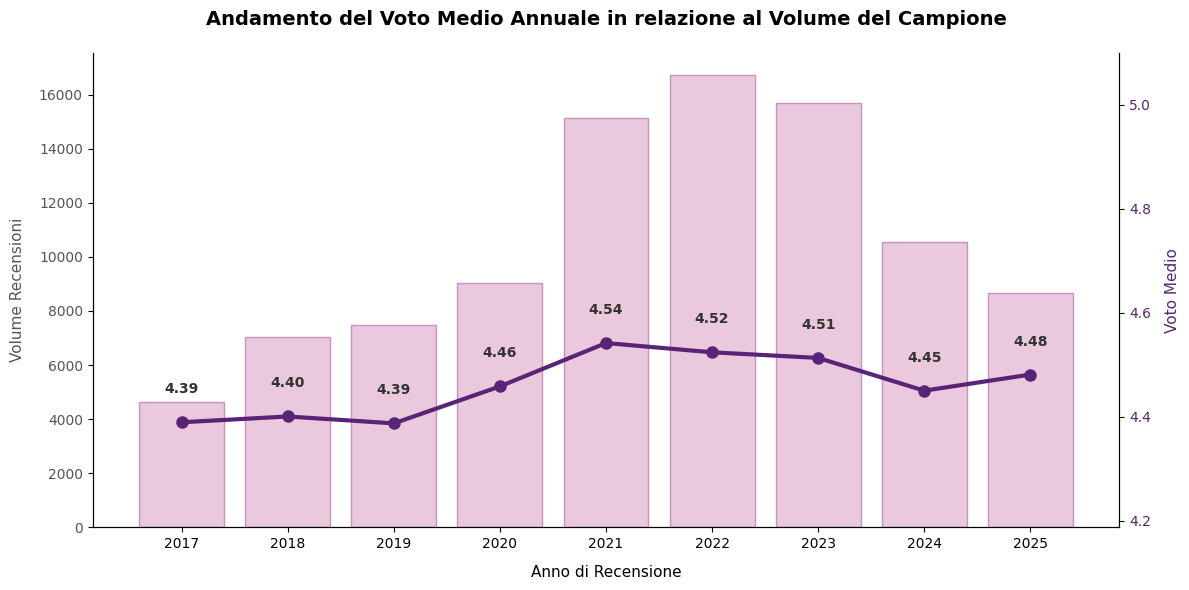

In [21]:
if 'Data Recensione' in df.columns and 'Voto Generale Recensione' in df.columns:
    display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))
    
    df_plot = df[['Data Recensione', 'Voto Generale Recensione']].dropna().copy()
    df_plot['Anno'] = df_plot['Data Recensione'].dt.year.astype(int)
    
    # Esclusione dell'anno in corso (parziale, non confrontabile con anni completi)
    anno_estrazione = df_plot['Anno'].max()
    df_plot = df_plot[df_plot['Anno'] < anno_estrazione]
    display(HTML(f"<p><i>Nota: l'anno <b>{anno_estrazione}</b> è escluso dall'analisi in quanto parziale (estrazione: aprile {anno_estrazione}).</i></p>"))

    # Calcoliamo contemporaneamente il Volume (count) e il Voto (mean)
    trend_combinato = df_plot.groupby('Anno').agg(Volume_Recensioni=('Voto Generale Recensione', 'count'), Voto_Medio=('Voto Generale Recensione', 'mean')).reset_index()
    
    # Creazione del grafico combinato (doppio asse y)
    fig, ax1 = plt.subplots(figsize=(12, 6)) 
    
    x = trend_combinato['Anno']
    y_vol = trend_combinato['Volume_Recensioni']
    y_voto = trend_combinato['Voto_Medio']
    
    # Asse sinistro: istogramma (il volume)
    color_vol = "#e4bcd3" 
    ax1.bar(x, y_vol, color=color_vol, edgecolor="#bf7eb7", label='Volume Recensioni', alpha=0.8)
    ax1.set_xlabel('Anno di Recensione', fontsize=11, labelpad=10)
    ax1.set_ylabel('Volume Recensioni', fontsize=11, color='#555555', labelpad=10)
    ax1.tick_params(axis='y', labelcolor='#555555')
    ax1.set_xticks(x)
    
    # Asse destro: linea (il voto medio)
    ax2 = ax1.twinx() 
    color_voto = "#592378" 
    ax2.plot(x, y_voto, color=color_voto, marker='o', linewidth=3, markersize=8, label='Voto Medio')
    ax2.set_ylabel('Voto Medio', fontsize=11, color=color_voto, labelpad=10)
    ax2.tick_params(axis='y', labelcolor=color_voto)
    
    # Zoom dinamico sull'asse destro (per esaltare i trend del voto)
    y_min = y_voto.min() - 0.2
    ax2.set_ylim(y_min, 5.1)
    
    # Aggiungiamo i numeri esatti del voto 
    for i, j in zip(x, y_voto):
        ax2.text(i, j + 0.05, f'{j:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#333333')
        
    plt.title('Andamento del Voto Medio Annuale in relazione al Volume del Campione', fontsize=14, fontweight='bold', pad=20)
    ax1.spines['top'].set_visible(False)
    ax2.spines['top'].set_visible(False)
    fig.tight_layout()
    plt.show()

else:
    display(HTML("<p style='color:red;'><b>Errore:</b> Colonne temporali o di voto non trovate nel dataset.</p>"))

## **Conclusioni e Salvataggio**

In [24]:
cartella_destinazione = os.path.join("Circular Second Hand", "Analisi", "Analisi - Recensioni", "Risultati Analisi - Recensioni")
if not os.path.exists(cartella_destinazione):
    os.makedirs(cartella_destinazione)

nome_file_pulito = f"1_cleaning__recensioni.csv"
percorso_salvataggio = os.path.join(cartella_destinazione, nome_file_pulito)
df.to_csv(percorso_salvataggio, index=False)

display(HTML("<hr style='border-top: 1px solid #d3d3d3;'>"))
display(HTML(f"""<h4><b>Salvataggio completato</b>:</h4> <ul>
             <li>Il dataset pulito e formattato è stato salvato con successo in: <b>{percorso_salvataggio}</b>.</li> </ul>"""))